<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Duplicates Lab**


Estimated time needed: **30** minutes


## Introduction


Data wrangling is a critical step in preparing datasets for analysis, and handling duplicates plays a key role in ensuring data accuracy. In this lab, you will focus on identifying and removing duplicate entries from your dataset. 


## Objectives


In this lab, you will perform the following:


1. Identify duplicate rows in the dataset and analyze their characteristics.
2. Visualize the distribution of duplicates based on key attributes.
3. Remove duplicate values strategically based on specific criteria.
4. Outline the process of verifying and documenting duplicate removal.


## Hands on Lab


Install the needed library


In [ ]:
!pip install pandas
!pip install matplotlib

Import pandas module


In [2]:
import pandas as pd


Import matplotlib


In [3]:
import matplotlib.pyplot as plt


## **Load the dataset into a dataframe**


<h2>Read Data</h2>
<p>
We utilize the <code>pandas.read_csv()</code> function for reading CSV files. However, in this version of the lab, which operates on JupyterLite, the dataset needs to be downloaded to the interface using the provided code below.
</p>


In [4]:
# Load the dataset directly from the URL
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/VYPrOu0Vs3I0hKLLjiPGrA/survey-data-with-duplicate.csv"
df = pd.read_csv(file_path)

# Display the first few rows
print(df.head())

   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

Load the data into a pandas dataframe:



Note: If you are working on a local Jupyter environment, you can use the URL directly in the pandas.read_csv() function as shown below:



In [6]:
# df = pd.read_csv("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv")


## Identify and Analyze Duplicates


### Task 1: Identify Duplicate Rows
1. Count the number of duplicate rows in the dataset.
3. Display the first few duplicate rows to understand their structure.


In [8]:
## Write your code here
# Count duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

# Display first few duplicate rows
duplicates = df[df.duplicated()]
print("\nFirst few duplicate rows:")
display(duplicates.head())

Number of duplicate rows: 20

First few duplicate rows:


,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
65437,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
65438,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
65439,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
65440,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
65441,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 2: Analysis of Duplicate Response Patterns
1. Identify duplicate response patterns based on selected columns such as MainBranch, Employment, and RemoteWork.
2. Clarify that these represent multiple respondents with identical answers rather than duplicate records. Analyse which other columns frequently share identical values within these response-pattern groups.
   


In [11]:
## Write your code here
# Columns defining response patterns
pattern_cols = ['MainBranch', 'Employment', 'RemoteWork']

# Count shared response patterns
pattern_counts = (
    df.groupby(pattern_cols)
      .size()
      .reset_index(name='Count')
      .sort_values('Count', ascending=False)
)

print("Most common response patterns:")
display(pattern_counts.head(10))

# Patterns shared by multiple respondents
shared_patterns = pattern_counts[pattern_counts['Count'] > 1]

print(f"\nNumber of response patterns shared by multiple respondents: {len(shared_patterns)}")

display(shared_patterns.head())

# Analyze consistency of other columns within shared-pattern groups
other_cols = [c for c in df.columns if c not in pattern_cols]

consistency_results = []

for col in other_cols:
    consistency = (
        df.groupby(pattern_cols)[col]
          .nunique(dropna=False)
          .eq(1)
          .mean()
    )
    
    consistency_results.append({
        'Column': col,
        'ConsistencyRate': consistency
    })

consistency_df = (
    pd.DataFrame(consistency_results)
      .sort_values('ConsistencyRate', ascending=False)
)

print("Columns most frequently identical within response-pattern groups:")
display(consistency_df.head(15))

Most common response patterns:


,MainBranch,Employment,RemoteWork,Count
0,I am a developer by profession,"Employed, full-time","Hybrid (some remote, some in-person)",15288
2,I am a developer by profession,"Employed, full-time",Remote,12196
1,I am a developer by profession,"Employed, full-time",In-person,7118
78,I am a developer by profession,"Independent contractor, freelancer, or self-em...",Remote,2815
8,I am a developer by profession,"Employed, full-time;Independent contractor, fr...",Remote,1754
232,"I am not primarily a developer, but I write co...","Employed, full-time","Hybrid (some remote, some in-person)",1479
6,I am a developer by profession,"Employed, full-time;Independent contractor, fr...","Hybrid (some remote, some in-person)",1169
76,I am a developer by profession,"Independent contractor, freelancer, or self-em...","Hybrid (some remote, some in-person)",990
233,"I am not primarily a developer, but I write co...","Employed, full-time",In-person,916
234,"I am not primarily a developer, but I write co...","Employed, full-time",Remote,695



Number of response patterns shared by multiple respondents: 319


,MainBranch,Employment,RemoteWork,Count
0,I am a developer by profession,"Employed, full-time","Hybrid (some remote, some in-person)",15288
2,I am a developer by profession,"Employed, full-time",Remote,12196
1,I am a developer by profession,"Employed, full-time",In-person,7118
78,I am a developer by profession,"Independent contractor, freelancer, or self-em...",Remote,2815
8,I am a developer by profession,"Employed, full-time;Independent contractor, fr...",Remote,1754


Columns most frequently identical within response-pattern groups:


,Column,ConsistencyRate
2,Check,1.000000
72,AINextMuch less integrated,0.763920
109,ConvertedCompYearly,0.657016
14,BuildvsBuy,0.648107
71,AINextLess integrated,0.648107
12,PurchaseInfluence,0.636971
18,CompTotal,0.628062
11,OrgSize,0.625835
17,Currency,0.614699
9,YearsCodePro,0.610245


### Task 3: Visualize Shared Response Patterns
1. Create visualizations to show the distribution of shared response patterns across different categories.
2. Use bar charts or pie charts to represent the distribution of respondents who share identical values for MainBranch, Employment, and RemoteWork, grouped by Country and Employment.


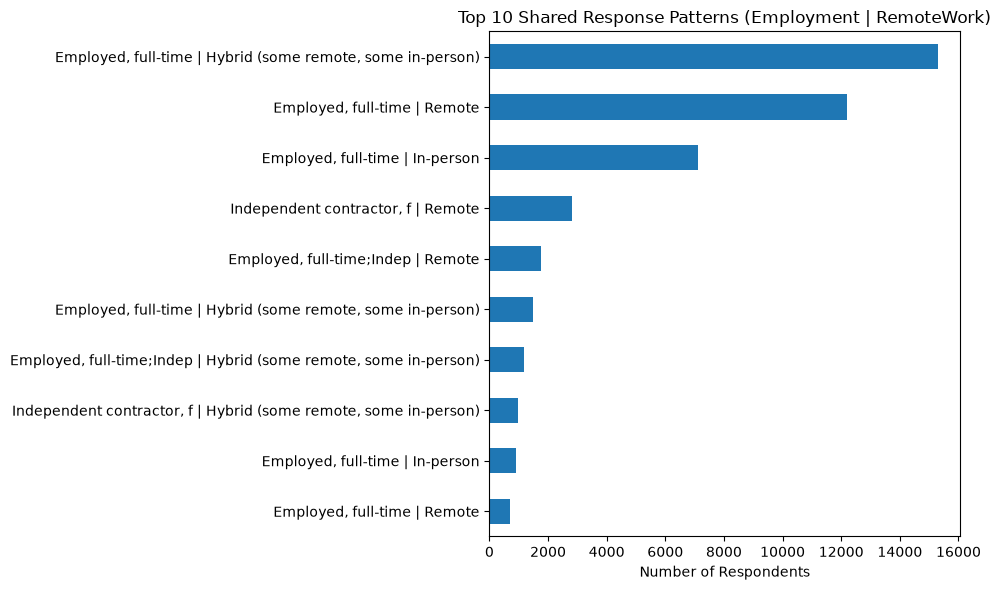

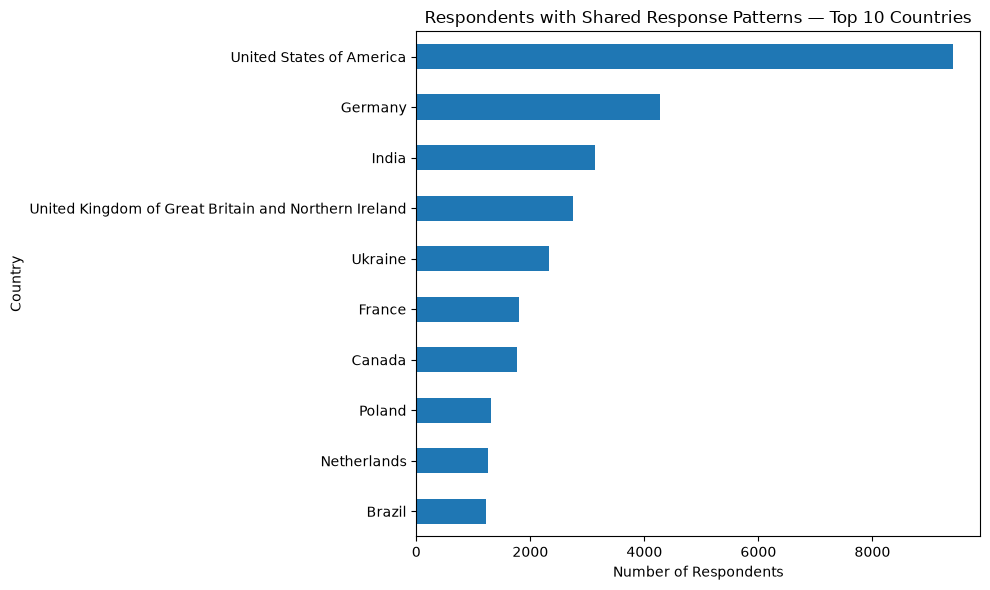

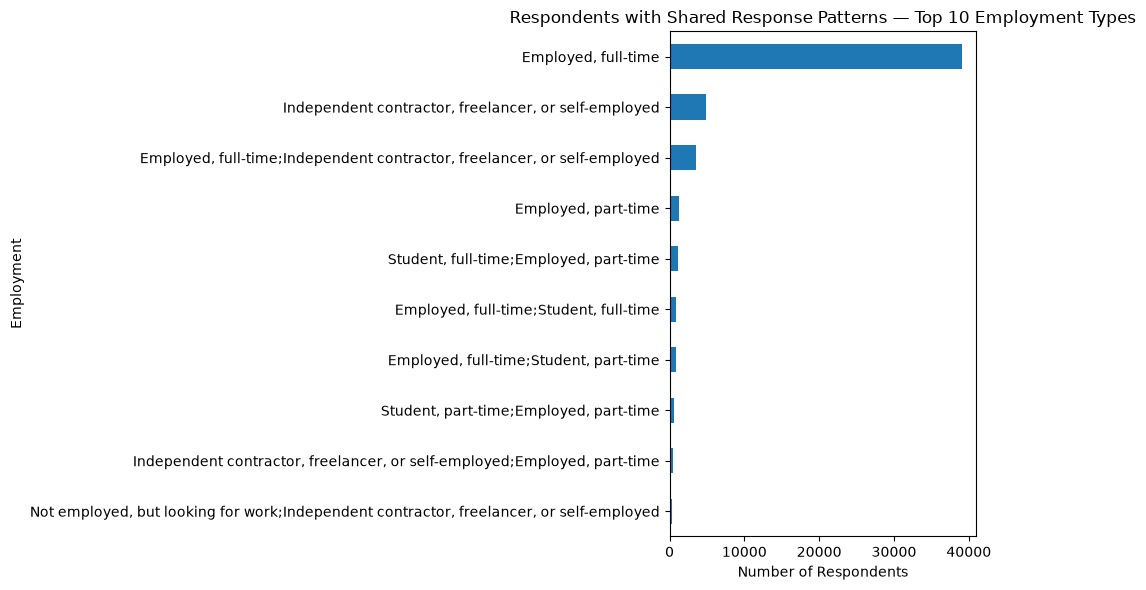

In [14]:
import matplotlib.pyplot as plt

# 1) Top 10 shared patterns, labeled with Employment AND RemoteWork
top_patterns = pattern_counts.head(10).copy()
top_patterns['Label'] = top_patterns['Employment'].str[:25] + " | " + top_patterns['RemoteWork']

top_patterns.plot(kind='barh', x='Label', y='Count', legend=False, figsize=(10, 6))
plt.title('Top 10 Shared Response Patterns (Employment | RemoteWork)')
plt.xlabel('Number of Respondents')
plt.ylabel('')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 2) Respondents in shared patterns, grouped by Country
shared_rows = df.merge(shared_patterns[pattern_cols], on=pattern_cols, how='inner')

shared_rows['Country'].value_counts().head(10).plot(kind='barh', figsize=(10, 6))
plt.title('Respondents with Shared Response Patterns — Top 10 Countries')
plt.xlabel('Number of Respondents')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# 3) Respondents in shared patterns, grouped by Employment
shared_rows['Employment'].value_counts().head(10).plot(kind='barh', figsize=(10, 6))
plt.title('Respondents with Shared Response Patterns — Top 10 Employment Types')
plt.xlabel('Number of Respondents')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [15]:
# Does ResponseId identify each record?
print("Duplicate ResponseIds:", df['ResponseId'].duplicated().sum())
print("Exact duplicate rows:", df.duplicated().sum())

Duplicate ResponseIds: 20
Exact duplicate rows: 20


### Task 4: Evaluate Duplicate Handling Strategy
1. Analyse the dataset to determine which column(s) define record uniqueness.
2. Assess whether removing rows based on a subset of columns (rather than complete row duplication) is appropriate.
Justify your decision with reference to the structure and purpose of the dataset.


In [16]:
# Remove exact duplicate rows and verify
df_clean = df.drop_duplicates()

print("Before:", df.shape)
print("After: ", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))
print("Duplicates left:", df_clean.duplicated().sum())
print("Duplicate ResponseIds left:", df_clean['ResponseId'].duplicated().sum())

Before: (65457, 114)
After:  (65437, 114)
Rows removed: 20
Duplicates left: 0
Duplicate ResponseIds left: 0


## Verify and Document Duplicate Removal Process


### Task 5: Documentation
1. Document the process of identifying and removing duplicates.


2. Explain the reasoning behind selecting specific columns for identifying and removing duplicates.


### Summary and Next Steps
**In this lab, you focused on identifying and analyzing duplicate rows within the dataset.**

- You employed various techniques to explore the nature of duplicates and applied strategic methods for their removal.
- For additional analysis, consider investigating the impact of duplicates on specific analyses and how their removal affects the results.
- This version of the lab is more focused on duplicate analysis and handling, providing a structured approach to deal with duplicates in a dataset effectively.


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-11- 05|1.3|Madhusudhan Moole|Updated lab|
|2024-10-28|1.2|Madhusudhan Moole|Updated lab|
|2024-09-24|1.1|Madhusudhan Moole|Updated lab|
|2024-09-23|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
